### 1- PYSR FOR SP_GR DATASET AAPLYING FIVE GROUP SPLITS

In [2]:
# ============================================================
# 1) IMPORTS + SETTINGS
# ============================================================
# استيراد المكتبات وتحديد SEED وإنشاء مجلد النتائج.

import os, pandas as pd, numpy as np
from pysr import PySRRegressor
from sklearn.model_selection import GroupShuffleSplit, GroupKFold
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

SEED=42; np.random.seed(SEED); os.makedirs("results",exist_ok=True)


# ============================================================
# 2) LOAD + CLEAN DATA
# ============================================================
# قراءة البيانات وتوحيد أسماء الأعمدة وحذف Missing وInfinity.

df=pd.read_csv("sp_gr_dataset_clean.csv")
df=df.rename(columns={"Specific Gravity":"SG","Pressure (psia)":"P","Hydrate Temperature (K)":"HFT"})
df=df[["SG","P","HFT"]].replace([np.inf,-np.inf],np.nan).dropna().reset_index(drop=True)
X=df[["SG","P"]].copy(); y=df["HFT"].astype(float).values

print("Shape:",df.shape); print("Columns:",X.columns.tolist()); print("\nMissing:\n",df.isna().sum()); print("\nDuplicates:",df.duplicated().sum()); 
display(df.describe())


# ============================================================
# 3) NEAR-CONDITION GROUPING
# ============================================================
# نفس طريقة Paper 1: تقريب SG وPressure إلى 3 منازل ثم إنشاء Group ID.

df["SG_round"]=df["SG"].round(3); df["P_round"]=df["P"].round(3)
df["group_id"]=df[["SG_round","P_round"]].astype(str).agg("_".join,axis=1)
groups=df["group_id"].to_numpy()

print("\nUnique samples:",len(df)); print("Unique groups:",df["group_id"].nunique()); print("Average samples/group:",len(df)/df["group_id"].nunique())


# ============================================================
# 4) GROUP DIAGNOSTICS
# ============================================================
# فحص عدد العينات داخل كل Group للتأكد من طبيعة الـgrouping.

group_sizes=df["group_id"].value_counts()
print("\nSingleton groups:",(group_sizes==1).sum()); print("Groups >1 sample:",(group_sizes>1).sum()); print("Largest group:",group_sizes.max())
display(group_sizes.describe()); display(group_sizes.head(10))


# ============================================================
# 5) GROUPED TRAIN / TEST SPLIT
# ============================================================
# تقسيم 80/20 مع منع ظهور نفس الـGroup في Training وTest.

gss=GroupShuffleSplit(n_splits=1,test_size=0.20,random_state=SEED); train_idx,test_idx=next(gss.split(X,y,groups))
X_train=X.iloc[train_idx].reset_index(drop=True); X_test=X.iloc[test_idx].reset_index(drop=True)
y_train=y[train_idx]; y_test=y[test_idx]; groups_train=groups[train_idx]; groups_test=groups[test_idx]

print("\nTotal:",len(df),"| Train:",len(train_idx),"| Unseen test:",len(test_idx)); print("Train groups:",len(np.unique(groups_train)),
                                                                                          "| Test groups:",len(np.unique(groups_test)))


# ============================================================
# 6) LEAKAGE CHECK
# ============================================================
# التأكد أن الـGroups في Test غير موجودة في Training.

overlap=set(groups_train)&set(groups_test); print("\nGroup overlap:",len(overlap)); assert len(overlap)==0; print("✓ No group leakage.")


# ============================================================
# 7) SAVE SPLIT + GROUPS
# ============================================================
# حفظ الـindices والـGroups لإعادة إنتاج نفس التجربة لاحقًا.

pd.DataFrame({"train_idx":train_idx}).to_csv("results/train_idx.csv",index=False)
pd.DataFrame({"test_idx":test_idx}).to_csv("results/test_idx.csv",index=False)
df[["SG","P","HFT","group_id"]].to_csv("results/group_assignments.csv",index=False)


# ============================================================
# 8) METRICS
# ============================================================
# RRMSE هو الـprimary error metric، مع RMSE وMAE وR² كـmetrics إضافية.

def metrics(y_true,y_pred):
    y_true=np.asarray(y_true,dtype=float); y_pred=np.asarray(y_pred,dtype=float)
    rmse=np.sqrt(mean_squared_error(y_true,y_pred)); mae=mean_absolute_error(y_true,y_pred); r2=r2_score(y_true,y_pred); 
    rrmse=100*rmse/np.mean(np.abs(y_true))
    return {"RMSE_K":rmse,"MAE_K":mae,"RRMSE_%":rrmse,"R2":r2}


# ============================================================
# 9) PySR MODEL
# ============================================================
# نضيف sqrt وlog بجانب العمليات الأساسية، مع زيادة بسيطة في حجم البحث.

def make_model():
    return PySRRegressor(niterations=150,populations=12,population_size=60,binary_operators=["+","-","*","/"],unary_operators=["sqrt","log"],
                         maxsize=25,model_selection="best",random_state=SEED,parallelism="serial",deterministic=True,progress=True)


# ============================================================
# 10) GROUPED 5-FOLD CV
# ============================================================
# كل Validation Fold يحتوي على Groups غير موجودة في Training Fold.

gkf=GroupKFold(n_splits=5); cv_results=[]; cv_equations=[]

for fold,(tr,va) in enumerate(gkf.split(X_train,y_train,groups_train),1):
    print(f"\n========== FOLD {fold} ==========")
    assert len(set(groups_train[tr])&set(groups_train[va]))==0
    model=make_model(); model.fit(X_train.iloc[tr],y_train[tr]); pred=np.asarray(model.predict(X_train.iloc[va])).ravel(); m=metrics(y_train[va],pred)
    cv_results.append({"Fold":fold,**m,"N_train":len(tr),"N_validation":len(va),"Train_groups":len(np.unique(groups_train[tr])),
                       "Validation_groups":len(np.unique(groups_train[va]))})
    eq=model.equations_.copy(); eq["Fold"]=fold; cv_equations.append(eq)
    print(f"RMSE={m['RMSE_K']:.5f} K | MAE={m['MAE_K']:.5f} K | RRMSE={m['RRMSE_%']:.5f}% | R²={m['R2']:.5f}"); print("Equation:",model.sympy())


# ============================================================
# 11) CV SUMMARY
# ============================================================
# تلخيص أداء الـ5 folds باستخدام mean/std/min/max.

cv=pd.DataFrame(cv_results); cv_eq=pd.concat(cv_equations,ignore_index=True)
print("\n=== GROUPED CV ==="); display(cv)
cv_summary=cv[["RMSE_K","MAE_K","RRMSE_%","R2"]].agg(["mean","std","min","max"]); print("\n=== CV SUMMARY ==="); display(cv_summary)


# ============================================================
# 12) FINAL PySR MODEL
# ============================================================
# تدريب المعادلة النهائية على كامل Training data فقط، مع ترك Test untouched.

final_model=make_model(); final_model.fit(X_train,y_train); equations=final_model.equations_.copy()
print("\n=== FINAL PARETO EQUATIONS ==="); display(equations[["complexity","loss","equation"]].sort_values("complexity"))


# ============================================================
# 13) SELECTED EQUATION
# ============================================================
# استخراج المعادلة المختارة وحفظها.

selected_equation=final_model.sympy(); print("\n=== SELECTED EQUATION ==="); print(selected_equation)
with open("results/selected_equation.txt","w",encoding="utf-8") as f: f.write(str(selected_equation))


# ============================================================
# 14) TRAINING PERFORMANCE
# ============================================================
# حساب أداء المعادلة على بيانات التدريب.

pred_train=np.asarray(final_model.predict(X_train)).ravel(); train_metrics=metrics(y_train,pred_train)
print("\n=== TRAINING PERFORMANCE ===")
for k,v in train_metrics.items(): print(f"{k}: {v:.6f}")


# ============================================================
# 15) UNSEEN-GROUP TEST
# ============================================================
# اختبار المعادلة على الـ20% التي لم تدخل في التدريب.

pred_test=np.asarray(final_model.predict(X_test)).ravel(); test_metrics=metrics(y_test,pred_test)
print("\n=== UNSEEN-GROUP TEST ===")
for k,v in test_metrics.items(): print(f"{k}: {v:.6f}")


# ============================================================
# 16) TRAINING vs UNSEEN TEST
# ============================================================
# مقارنة مباشرة بين الأداء داخل التدريب وخارج التدريب.

comparison=pd.DataFrame({"Dataset":["Training","Unseen Groups"],"RMSE_K":[train_metrics["RMSE_K"],test_metrics["RMSE_K"]],
                         "MAE_K":[train_metrics["MAE_K"],test_metrics["MAE_K"]],"RRMSE_%":[train_metrics["RRMSE_%"],test_metrics["RRMSE_%"]],
                         "R2":[train_metrics["R2"],test_metrics["R2"]]})
print("\n=== TRAINING vs UNSEEN TEST ==="); display(comparison)


# ============================================================
# 17) GENERALIZATION GAP
# ============================================================
# حساب الفرق بين Training وUnseen Test لتقييم مقدار تغير الأداء.

generalization_gap=pd.DataFrame({"Metric":["RMSE_K","MAE_K","RRMSE_%","R2"],"Train":[train_metrics["RMSE_K"],train_metrics["MAE_K"],
                                                                                     train_metrics["RRMSE_%"],train_metrics["R2"]],
                                 "Unseen":[test_metrics["RMSE_K"],test_metrics["MAE_K"],test_metrics["RRMSE_%"],test_metrics["R2"]]})
generalization_gap["Difference"]=generalization_gap["Unseen"]-generalization_gap["Train"]
print("\n=== GENERALIZATION GAP ==="); display(generalization_gap)


# ============================================================
# 18) ROW-LEVEL UNSEEN PREDICTIONS
# ============================================================
# إنشاء جدول تفصيلي لكل نقطة في الـUnseen Test.

test_eval=X_test.copy(); test_eval["Actual_HFT"]=y_test; test_eval["Predicted_HFT"]=pred_test; test_eval["Residual_K"]=y_test-pred_test; 
test_eval["Abs_Error_K"]=np.abs(test_eval["Residual_K"]); test_eval["Relative_Error_%"]=100*test_eval["Abs_Error_K"]/np.abs(test_eval["Actual_HFT"]);
test_eval["Group"]=groups_test
print("\n=== UNSEEN PREDICTIONS ==="); display(test_eval.head(10))


# ============================================================
# 19) GROUP-WISE PERFORMANCE
# ============================================================
# حساب الأداء لكل Group في الـUnseen Test لمعرفة اختلاف التعميم بين الظروف.

group_results=[]
for g,d in test_eval.groupby("Group"):
    m=metrics(d["Actual_HFT"],d["Predicted_HFT"]); group_results.append({"Group":g,"N":len(d),**m,
                                                                         "Mean_Abs_Error_K":d["Abs_Error_K"].mean(),
                                                                         "Max_Abs_Error_K":d["Abs_Error_K"].max()})

group_results=pd.DataFrame(group_results); print("\n=== UNSEEN GROUP RESULTS ==="); display(group_results.sort_values("RRMSE_%"))


# ============================================================
# 20) RESIDUAL DIAGNOSTICS
# ============================================================
# فحص متوسط واتجاه وتشتت الـResiduals على الـUnseen Test.

residual_summary=pd.DataFrame({"Metric":["Mean residual (K)","Median residual (K)","Std residual (K)","Max positive residual (K)",
                                         "Max negative residual (K)","Mean absolute error (K)"],"Value":[test_eval["Residual_K"].mean(),
                                                                                                         test_eval["Residual_K"].median(),
                                                                                                         test_eval["Residual_K"].std(),
                                                                                                         test_eval["Residual_K"].max(),
                                                                                                         test_eval["Residual_K"].min(),
                                                                                                         test_eval["Abs_Error_K"].mean()]})
print("\n=== RESIDUAL DIAGNOSTICS ==="); display(residual_summary)


# ============================================================
# 21) PREDICTION SANITY CHECK
# ============================================================
# التأكد من عدم وجود NaN أو Infinity في نتائج PySR.

print("\n=== SANITY CHECK ==="); print("NaN:",np.isnan(pred_test).sum()); print("Inf:",
                                                                                np.isinf(pred_test).sum()); print("Min predicted HFT:", 
                                                                                                                  pred_test.min()); 
print("Max predicted HFT:",pred_test.max()); assert np.isfinite(pred_test).all(); print("✓ Predictions are finite.")


# ============================================================
# 22) SAVE ALL RESULTS
# ============================================================
# حفظ كل النتائج المهمة: CV، المعادلات، predictions، group analysis، residuals.

cv.to_csv("results/pysr_grouped_cv.csv",index=False)
cv_eq.to_csv("results/pysr_grouped_cv_equations.csv",index=False)
equations.to_csv("results/pysr_pareto_equations.csv",index=False)
comparison.to_csv("results/train_vs_unseen_test.csv",index=False)
generalization_gap.to_csv("results/generalization_gap.csv",index=False)
test_eval.to_csv("results/unseen_test_predictions.csv",index=False)
group_results.to_csv("results/unseen_group_results.csv",index=False)
residual_summary.to_csv("results/residual_diagnostics.csv",index=False)
cv_summary.to_csv("results/cv_summary.csv")
print("\n========================================"); print("✓ ALL RESULTS SAVED IN ./results/"); print("========================================")

Shape: (3811, 3)
Columns: ['SG', 'P']

Missing:
 SG     0
P      0
HFT    0
dtype: int64

Duplicates: 0


,SG,P,HFT
count,3811.000000,3811.000000,3811.000000
mean,0.771843,1267.527123,285.101303
std,0.150484,1105.920095,13.365370
min,0.550000,12.975040,225.609400
25%,0.644894,239.223674,278.575438
50%,0.720354,1048.294674,289.769400
75%,0.867174,1983.706000,293.854289
max,1.200000,3987.977258,302.611879



Unique samples: 3811
Unique groups: 3803
Average samples/group: 1.0021036024191428

Singleton groups: 3795
Groups >1 sample: 8
Largest group: 2


count    3803.000000
mean        1.002104
std         0.045823
min         1.000000
25%         1.000000
50%         1.000000
75%         1.000000
max         2.000000
Name: group_id, dtype: float64

0.646_135.725     2
1.04_647.0        2
1.2_377.1         2
0.685_1743.77     2
0.641_123.208     2
0.734_122.283     2
1.2_997.0         2
0.808_1702.439    2
0.624_3182.071    1
0.797_3708.066    1
Name: group_id, dtype: int64


Total: 3811 | Train: 3048 | Unseen test: 763
Train groups: 3042 | Test groups: 761

Group overlap: 0
✓ No group leakage.

========== FOLD 1 ==========
RMSE=2.78595 K | MAE=1.97445 K | RRMSE=0.97862% | R²=0.95859
Equation: 338.88034 - 373.61768/(SG + log(P))

========== FOLD 2 ==========
RMSE=2.52082 K | MAE=1.81564 K | RRMSE=0.88176% | R²=0.96326
Equation: 338.86517 - 373.4126/(SG + log(P))

========== FOLD 3 ==========
RMSE=2.77077 K | MAE=2.00410 K | RRMSE=0.97141% | R²=0.95525
Equation: 338.60312 - 371.94202/(SG + log(P))

========== FOLD 4 ==========
RMSE=2.75860 K | MAE=1.89830 K | RRMSE=0.96911% | R²=0.96121
Equation: 327.17892 - 245.01595/log(P*SG)

========== FOLD 5 ==========
RMSE=2.72386 K | MAE=1.96364 K | RRMSE=0.95632% | R²=0.96097
Equation: 338.83237 - 373.54523/(SG + log(P))

=== GROUPED CV ===


... (15 outputs left out)


=== RESIDUAL DIAGNOSTICS ===


,Metric,Value
0,Mean residual (K),-0.115466
1,Median residual (K),-0.087496
2,Std residual (K),2.846944
3,Max positive residual (K),11.244682
4,Max negative residual (K),-10.394356
5,Mean absolute error (K),2.042853



=== SANITY CHECK ===
NaN: 0
Inf: 0
Min predicted HFT: 226.34755990728033
Max predicted HFT: 298.1566162685881
✓ Predictions are finite.


PermissionError: [Errno 13] Permission denied: 'results/unseen_test_predictions.csv'

### 1-1- APPLYING THE BEST FOUR PSYR EQUATIONS FOR THE UNSEEN TEST DATA

In [3]:
# ============================================================
# 1) IMPORTS + SETTINGS
# ============================================================
# اختبار 4 معادلات PySR على نفس الـUnseen Test.

import os, numpy as np, pandas as pd
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

os.makedirs("results",exist_ok=True)


# ============================================================
# 2) LOAD DATA + SAME UNSEEN TEST
# ============================================================
# استخدام نفس test_idx المحفوظ سابقًا لضمان عدم تغيير الـUnseen Test.

df=pd.read_csv("sp_gr_dataset_clean.csv")
df=df.rename(columns={"Specific Gravity":"SG","Pressure (psia)":"P","Hydrate Temperature (K)":"HFT"})
df=df[["SG","P","HFT"]].replace([np.inf,-np.inf],np.nan).dropna().reset_index(drop=True)

test_idx=pd.read_csv("results/test_idx.csv")["test_idx"].values
test=df.iloc[test_idx].copy().reset_index(drop=True)

SG=test["SG"].values.astype(float)
P=test["P"].values.astype(float)
y=test["HFT"].values.astype(float)

print("Unseen Test samples:",len(test))
print("SG range:",SG.min(),"to",SG.max())
print("P range:",P.min(),"to",P.max())
print("HFT range:",y.min(),"to",y.max())


# ============================================================
# 3) DEFINE THE FOUR EQUATIONS
# ============================================================
# المعادلات مأخوذة مباشرة من Pareto front الذي أرسلته.

def E1(SG,P):
    return -276.91644/np.log(P)+330.3014

def E2(SG,P):
    return -372.36154/(np.log(P)+SG)+338.67386

def E3(SG,P):
    return -214.6411/np.sqrt(SG*np.log(P))-49.40507*SG+422.33377

def E4(SG,P):
    inside_log=P-np.log(P-12.062217)/(SG-0.24531157)
    inside_sqrt=SG*np.log(inside_log)
    return -203.8513/np.sqrt(inside_sqrt)-47.008713*SG+415.93082

equations={
    "E1_C6":E1,
    "E2_C8":E2,
    "E3_C13":E3,
    "E4_C22":E4
}


# ============================================================
# 4) METRICS
# ============================================================
# RRMSE هو الـprimary metric، مع RMSE وMAE وR².

def calc_metrics(y_true,y_pred):
    y_true=np.asarray(y_true,float)
    y_pred=np.asarray(y_pred,float)
    mask=np.isfinite(y_pred)
    yt=y_true[mask]
    yp=y_pred[mask]
    rmse=np.sqrt(mean_squared_error(yt,yp))
    mae=mean_absolute_error(yt,yp)
    rrmse=100*rmse/np.mean(np.abs(yt))
    r2=r2_score(yt,yp) if len(yt)>1 else np.nan
    return {"N_valid":len(yt),"RMSE_K":rmse,"MAE_K":mae,"RRMSE_%":rrmse,"R2":r2,"Invalid":len(y_true)-len(yt)}


# ============================================================
# 5) TEST THE FOUR EQUATIONS
# ============================================================
# حساب Predictions وMetrics لكل معادلة على نفس Unseen Test.

results=[]
predictions=test[["SG","P","HFT"]].copy()

for name,eq in equations.items():
    try:
        pred=np.asarray(eq(SG,P),dtype=float).ravel()
        m=calc_metrics(y,pred)
        results.append({"Equation":name,"Complexity":{"E1_C6":6,"E2_C8":8,"E3_C13":13,"E4_C22":22}[name],**m})
        predictions[f"{name}_Predicted"]=pred
        predictions[f"{name}_Residual"]=y-pred
    except Exception as e:
        print(f"{name} ERROR:",e)
        results.append({"Equation":name,"Complexity":{"E1_C6":6,"E2_C8":8,"E3_C13":13,"E4_C22":22}[name],"N_valid":0,"RMSE_K":np.nan,"MAE_K":np.nan,"RRMSE_%":np.nan,"R2":np.nan,"Invalid":len(y)})


# ============================================================
# 6) COMPARISON TABLE
# ============================================================
# مقارنة مباشرة بين الأربع معادلات على Unseen Test.

comparison=pd.DataFrame(results).sort_values("Complexity").reset_index(drop=True)

print("\n================================================")
print("      FOUR EQUATIONS — UNSEEN TEST")
print("================================================")
display(comparison)


# ============================================================
# 7) GENERALIZATION-ORIENTED COMPARISON
# ============================================================
# عرض النتائج الأساسية فقط بترتيب التعقيد.

print("\n=== RRMSE COMPARISON ===")
display(comparison[["Equation","Complexity","RRMSE_%","RMSE_K","MAE_K","R2","Invalid"]])


# ============================================================
# 8) SAVE RESULTS
# ============================================================
# حفظ المقارنة والتنبؤات لاستخدامها لاحقًا في الورقة.

comparison.to_csv("results/four_equations_unseen_comparison.csv",index=False)
predictions.to_csv("results/four_equations_unseen_predictions.csv",index=False)

print("\n✓ Results saved:")
print("results/four_equations_unseen_comparison.csv")
print("results/four_equations_unseen_predictions.csv")


# ============================================================
# 9) DOMAIN CHECK — ESPECIALLY E4
# ============================================================
# فحص صلاحية المجال الرياضي لكل معادلة على Unseen Test.

print("\n=== DOMAIN / VALIDITY CHECK ===")

for name,eq in equations.items():
    try:
        pred=np.asarray(eq(SG,P),dtype=float)
        valid=np.isfinite(pred)
        print(f"{name}: Valid={valid.sum()} | Invalid={(~valid).sum()} | Min={np.nanmin(pred):.3f} K | Max={np.nanmax(pred):.3f} K")
    except Exception as e:
        print(f"{name}: DOMAIN ERROR -> {e}")


# ============================================================
# 10) BEST GENERALIZING EQUATION BY RRMSE
# ============================================================
# استخراج أقل RRMSE على Unseen Test — للاستخدام التحليلي فقط.

valid_comparison=comparison[comparison["Invalid"]==0].copy()

if len(valid_comparison)>0:
    best=valid_comparison.loc[valid_comparison["RRMSE_%"].idxmin()]
    print("\n=== LOWEST UNSEEN-TEST RRMSE ===")
    print(best[["Equation","Complexity","RRMSE_%","RMSE_K","MAE_K","R2"]])

Unseen Test samples: 763
SG range: 0.55 to 1.2
P range: 13.13207 to 3964.655088
HFT range: 225.6669 to 301.4143005

      FOUR EQUATIONS — UNSEEN TEST


,Equation,Complexity,N_valid,RMSE_K,MAE_K,RRMSE_%,R2,Invalid
0,E1_C6,6,763,3.349711,2.526954,1.174171,0.928765,0
1,E2_C8,8,763,2.847420,2.042853,0.998103,0.948527,0
2,E3_C13,13,763,2.630573,1.847069,0.922092,0.956068,0
3,E4_C22,22,763,2.548133,1.776238,0.893194,0.958779,0



=== RRMSE COMPARISON ===


,Equation,Complexity,RRMSE_%,RMSE_K,MAE_K,R2,Invalid
0,E1_C6,6,1.174171,3.349711,2.526954,0.928765,0
1,E2_C8,8,0.998103,2.847420,2.042853,0.948527,0
2,E3_C13,13,0.922092,2.630573,1.847069,0.956068,0
3,E4_C22,22,0.893194,2.548133,1.776238,0.958779,0



✓ Results saved:
results/four_equations_unseen_comparison.csv
results/four_equations_unseen_predictions.csv

=== DOMAIN / VALIDITY CHECK ===
E1_C6: Valid=763 | Invalid=0 | Min=222.763 K | Max=296.878 K
E2_C8: Valid=763 | Invalid=0 | Min=226.348 K | Max=298.157 K
E3_C13: Valid=763 | Invalid=0 | Min=226.073 K | Max=299.433 K
E4_C22: Valid=763 | Invalid=0 | Min=223.671 K | Max=299.118 K

=== LOWEST UNSEEN-TEST RRMSE ===
Equation        E4_C22
Complexity          22
RRMSE_%       0.893194
RMSE_K        2.548133
MAE_K         1.776238
R2            0.958779
Name: 3, dtype: object


### 1-2 EVALUATION PSYR ON EXTERNAL VALIDATION 

In [4]:
# ==========================================================
# SALMAN — SYMBOLIC REGRESSION EXTERNAL VALIDATION
# ==========================================================

import numpy as np
import pandas as pd
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# ==========================================================
# 1) MOLECULAR WEIGHTS
# ==========================================================

MW={"CH4":16.043,"CO2":44.010,"C2":30.070,"C3":44.097,"iC4":58.124,"nC4":58.124,"iC5":72.151,"nC5":72.151,"C6":86.178,"C7":100.205}

# ==========================================================
# 2) SALMAN GAS COMPOSITION (%)
# ==========================================================

comp={"CH4":74.10,"CO2":3.95,"C2":10.82,"C3":6.70,"iC4":0.94,"nC4":2.04,"iC5":0.53,"nC5":0.58,"C6":0.25,"C7":0.08}

# ==========================================================
# 3) CALCULATE MIXTURE MW AND SPECIFIC GRAVITY
# ==========================================================

mw_mix=sum(comp[k]*MW[k] for k in comp)/100
SP_GR=mw_mix/28.97

print(f"Mixture MW  = {mw_mix:.6f}")
print(f"SP_GR       = {SP_GR:.6f}")

# ==========================================================
# 4) PRESSURE + EXPERIMENTAL HFT
# ==========================================================

pressure=np.array([700.00,891.67,1083.33,1275.00,1466.67,1658.33,1850.00,2041.67,2233.33,2425.00,2616.67,2808.33,3000.00])

experimental=np.array([289.86,291.93,293.02,293.68,294.26,294.79,295.26,295.68,296.07,296.44,296.79,297.13,297.49])

SG=np.full_like(pressure,SP_GR,dtype=float)
P=pressure.astype(float)

# ==========================================================
# 5) FOUR SELECTED PySR EQUATIONS
# ==========================================================

def E1_C6(SG,P):
    return -276.91644/np.log(P)+330.3014

def E2_C8(SG,P):
    return -372.36154/(np.log(P)+SG)+338.67386

def E3_C13(SG,P):
    return -214.6411/np.sqrt(SG*np.log(P))-49.40507*SG+422.33377

def E4_C22(SG,P):
    inside_log=P-np.log(P-12.062217)/(SG-0.24531157)
    inside_sqrt=SG*np.log(inside_log)
    return -203.8513/np.sqrt(inside_sqrt)-47.008713*SG+415.93082

equations={"E1_C6":E1_C6,"E2_C8":E2_C8,"E3_C13":E3_C13,"E4_C22":E4_C22}

# ==========================================================
# 6) METRICS
# ==========================================================

def calc_metrics(y_true,y_pred):
    rmse=np.sqrt(mean_squared_error(y_true,y_pred))
    mae=mean_absolute_error(y_true,y_pred)
    rrmse=100*rmse/np.mean(np.abs(y_true))
    r2=r2_score(y_true,y_pred)
    return rmse,mae,rrmse,r2

# ==========================================================
# 7) PREDICTIONS + EXTERNAL VALIDATION RESULTS
# ==========================================================

results=[]
result_table=pd.DataFrame({"Pressure_psia":P,"SP_GR":SG,"Experimental_HFT_K":experimental})

for name,eq in equations.items():
    pred=np.asarray(eq(SG,P),dtype=float)
    rmse,mae,rrmse,r2=calc_metrics(experimental,pred)

    results.append({
        "Equation":name,
        "Complexity":{"E1_C6":6,"E2_C8":8,"E3_C13":13,"E4_C22":22}[name],
        "RMSE_K":rmse,
        "MAE_K":mae,
        "RRMSE_%":rrmse,
        "R2":r2,
        "Invalid":np.sum(~np.isfinite(pred))
    })

    result_table[f"{name}_Predicted_HFT_K"]=pred
    result_table[f"{name}_Residual_K"]=experimental-pred

# ==========================================================
# 8) SUMMARY
# ==========================================================

summary=pd.DataFrame(results).sort_values("Complexity").reset_index(drop=True)

print("\n==========================================================")
print("             SALMAN — EXTERNAL VALIDATION")
print("==========================================================")
print(summary.to_string(index=False))

# ==========================================================
# 9) DETAILED PREDICTIONS
# ==========================================================

print("\n==========================================================")
print("             SALMAN — PREDICTIONS")
print("==========================================================")
print(result_table.round(4).to_string(index=False))

# ==========================================================
# 10) DOMAIN CHECK
# ==========================================================

print("\n==========================================================")
print("             DOMAIN CHECK")
print("==========================================================")

for name,eq in equations.items():
    pred=np.asarray(eq(SG,P),dtype=float)
    print(f"{name}: Invalid={np.sum(~np.isfinite(pred))} | Min={pred.min():.3f} K | Max={pred.max():.3f} K")

# ==========================================================
# 11) SAVE RESULTS
# ==========================================================

summary.to_csv("results/salman_equations_comparison.csv",index=False)
result_table.to_csv("results/salman_equations_predictions.csv",index=False)

print("\n✓ Saved:")
print("results/salman_equations_comparison.csv")
print("results/salman_equations_predictions.csv")

Mixture MW  = 22.662911
SP_GR       = 0.782289

             SALMAN — EXTERNAL VALIDATION
Equation  Complexity   RMSE_K    MAE_K  RRMSE_%       R2  Invalid
   E1_C6           6 1.895250 1.880004 0.642893 0.212135        0
   E2_C8           8 1.632413 1.575922 0.553736 0.415508        0
  E3_C13          13 0.657147 0.527695 0.222913 0.905279        0
  E4_C22          22 0.610860 0.453361 0.207212 0.918153        0

             SALMAN — PREDICTIONS
 Pressure_psia  SP_GR  Experimental_HFT_K  E1_C6_Predicted_HFT_K  E1_C6_Residual_K  E2_C8_Predicted_HFT_K  E2_C8_Residual_K  E3_C13_Predicted_HFT_K  E3_C13_Residual_K  E4_C22_Predicted_HFT_K  E4_C22_Residual_K
        700.00 0.7823              289.86               288.0311            1.8289               287.8975            1.9625                288.8707             0.9893                288.9878             0.8722
        891.67 0.7823              291.93               289.5370            2.3930               289.5197            2.4103  

In [5]:
# ==========================================================
# LEVAN #3 — EXTERNAL VALIDATION
# ==========================================================

import numpy as np
import pandas as pd
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score


# ==========================================================
# 1) MOLECULAR WEIGHTS
# ==========================================================

MW={"CH4":16.043,"CO2":44.010,"C2":30.070,"C3":44.097,"iC4":58.124,"nC4":58.124,"iC5":72.151,"nC5":72.151,"C6":86.178,"C7":100.205}


# ==========================================================
# 2) LEVAN #3 GAS COMPOSITION (%)
# ==========================================================

CH4=89.19
CO2=4.44
C2=4.24
C3=1.14
iC4=0.28
nC4=0.30
iC5=0.15
nC5=0.10
C6=0.09
C7=0.07

N2=0.0
H2S=0.0
Water=0.0


# ==========================================================
# 3) PRESSURE
# ==========================================================

pressure=np.array([690.00,878.33,1066.67,1255.00,1443.33,1631.67,1820.00,2008.33,2196.67,2385.00,2573.33,2761.67,2950.00])


# ==========================================================
# 4) EXPERIMENTAL HFT
# ==========================================================

experimental=np.array([285.90,287.32,288.52,289.64,290.60,291.37,291.98,292.48,292.90,293.30,293.69,294.07,294.45])


# ==========================================================
# 5) CALCULATE MIXTURE MW + SPECIFIC GRAVITY
# ==========================================================

mw_mix=(CH4*MW["CH4"]+CO2*MW["CO2"]+C2*MW["C2"]+C3*MW["C3"]+iC4*MW["iC4"]+nC4*MW["nC4"]+iC5*MW["iC5"]+nC5*MW["nC5"]+C6*MW["C6"]+C7*MW["C7"])/100

SP_GR=mw_mix/28.97

print(f"Mixture MW = {mw_mix:.6f}")
print(f"SP_GR      = {SP_GR:.6f}")


# ==========================================================
# 6) PREPARE INPUTS
# ==========================================================

P=pressure.astype(float)
SG=np.full_like(P,SP_GR,dtype=float)
y=experimental.astype(float)

print(f"\nNumber of points = {len(P)}")
print(f"Pressure range   = {P.min():.2f}–{P.max():.2f} psia")
print(f"SP_GR            = {SP_GR:.6f}")
print(f"HFT range        = {y.min():.2f}–{y.max():.2f} K")


# ==========================================================
# 7) FOUR SELECTED PySR EQUATIONS
# ==========================================================

def E1_C6(SG,P):
    return -276.91644/np.log(P)+330.3014

def E2_C8(SG,P):
    return -372.36154/(np.log(P)+SG)+338.67386

def E3_C13(SG,P):
    return -214.6411/np.sqrt(SG*np.log(P))-49.40507*SG+422.33377

def E4_C22(SG,P):
    inside_log=P-np.log(P-12.062217)/(SG-0.24531157)
    inside_sqrt=SG*np.log(inside_log)
    return -203.8513/np.sqrt(inside_sqrt)-47.008713*SG+415.93082

equations={"E1_C6":E1_C6,"E2_C8":E2_C8,"E3_C13":E3_C13,"E4_C22":E4_C22}

complexities={"E1_C6":6,"E2_C8":8,"E3_C13":13,"E4_C22":22}


# ==========================================================
# 8) METRICS
# ==========================================================

def calc_metrics(y_true,y_pred):
    rmse=np.sqrt(mean_squared_error(y_true,y_pred))
    mae=mean_absolute_error(y_true,y_pred)
    rrmse=100*rmse/np.mean(np.abs(y_true))
    r2=r2_score(y_true,y_pred)
    return rmse,mae,rrmse,r2


# ==========================================================
# 9) EXTERNAL VALIDATION
# ==========================================================

results=[]
prediction_table=pd.DataFrame({"Pressure_psia":P,"SP_GR":SG,"Experimental_HFT_K":y})

for name,eq in equations.items():
    pred=np.asarray(eq(SG,P),dtype=float)
    invalid=np.sum(~np.isfinite(pred))

    if invalid==0:
        rmse,mae,rrmse,r2=calc_metrics(y,pred)
    else:
        valid=np.isfinite(pred)
        rmse,mae,rrmse,r2=calc_metrics(y[valid],pred[valid])

    results.append({"Equation":name,"Complexity":complexities[name],"RMSE_K":rmse,"MAE_K":mae,"RRMSE_%":rrmse,"R2":r2,"Invalid":invalid})

    prediction_table[f"{name}_Predicted_HFT_K"]=pred
    prediction_table[f"{name}_Residual_K"]=y-pred
    prediction_table[f"{name}_Abs_Error_K"]=np.abs(y-pred)


# ==========================================================
# 10) SUMMARY
# ==========================================================

summary=pd.DataFrame(results).sort_values("Complexity").reset_index(drop=True)

print("\n==========================================================")
print("             LEVAN #3 — EXTERNAL VALIDATION")
print("==========================================================")
print(summary.to_string(index=False))


# ==========================================================
# 11) DETAILED PREDICTIONS
# ==========================================================

print("\n==========================================================")
print("             LEVAN #3 — PREDICTIONS")
print("==========================================================")
print(prediction_table.round(4).to_string(index=False))


# ==========================================================
# 12) DOMAIN CHECK
# ==========================================================

print("\n==========================================================")
print("             DOMAIN CHECK")
print("==========================================================")

for name,eq in equations.items():
    pred=np.asarray(eq(SG,P),dtype=float)
    valid=np.isfinite(pred)

    print(f"{name}: Invalid={np.sum(~valid)} | Min={np.nanmin(pred):.3f} K | Max={np.nanmax(pred):.3f} K")


# ==========================================================
# 13) SAVE RESULTS
# ==========================================================

summary.to_csv("results/levan3_equations_comparison.csv",index=False)
prediction_table.to_csv("results/levan3_equations_predictions.csv",index=False)

print("\n✓ Saved:")
print("results/levan3_equations_comparison.csv")
print("results/levan3_equations_predictions.csv")

Mixture MW = 18.705670
SP_GR      = 0.645691

Number of points = 13
Pressure range   = 690.00–2950.00 psia
SP_GR            = 0.645691
HFT range        = 285.90–294.45 K

             LEVAN #3 — EXTERNAL VALIDATION
Equation  Complexity   RMSE_K    MAE_K  RRMSE_%       R2  Invalid
   E1_C6           6 1.620499 1.591027 0.556399 0.610588        0
   E2_C8           8 1.114494 1.110928 0.382662 0.815810        0
  E3_C13          13 1.062162 0.982723 0.364694 0.832701        0
  E4_C22          22 1.028424 0.984527 0.353110 0.843160        0

             LEVAN #3 — PREDICTIONS
 Pressure_psia  SP_GR  Experimental_HFT_K  E1_C6_Predicted_HFT_K  E1_C6_Residual_K  E1_C6_Abs_Error_K  E2_C8_Predicted_HFT_K  E2_C8_Residual_K  E2_C8_Abs_Error_K  E3_C13_Predicted_HFT_K  E3_C13_Residual_K  E3_C13_Abs_Error_K  E4_C22_Predicted_HFT_K  E4_C22_Residual_K  E4_C22_Abs_Error_K
        690.00 0.6457              285.90               287.9380           -2.0380             2.0380               286.8301      

In [6]:
# ==========================================================
# SAMPLE 11 — EXTERNAL VALIDATION
# ==========================================================

import numpy as np
import pandas as pd
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score


# ==========================================================
# 1) MOLECULAR WEIGHTS
# ==========================================================

MW={"CH4":16.043,"CO2":44.010,"C2":30.070,"C3":44.097,"iC4":58.124,"nC4":58.124,"iC5":72.151,"nC5":72.151,"C6":86.178,"C7":100.205}


# ==========================================================
# 2) SAMPLE 11 GAS COMPOSITION (%)
# ==========================================================

CH4=77.61
CO2=6.14
C2=8.81
C3=3.37
iC4=0.75
nC4=1.33
iC5=0.44
nC5=0.69
C6=0.86
C7=0.00

Water=0.0
N2=0.0
H2S=0.0


# ==========================================================
# 3) PRESSURE
# ==========================================================

pressure=np.array([590.00,702.22,814.44,926.67,1038.89,1151.11,1263.33,1375.56,1487.78,1600.00])


# ==========================================================
# 4) EXPERIMENTAL HFT
# ==========================================================

experimental=np.array([287.94,289.30,290.32,291.09,291.66,292.12,292.54,292.98,293.53,294.26])


# ==========================================================
# 5) CALCULATE MIXTURE MW + SPECIFIC GRAVITY
# ==========================================================

mw_mix=(CH4*MW["CH4"]+CO2*MW["CO2"]+C2*MW["C2"]+C3*MW["C3"]+iC4*MW["iC4"]+nC4*MW["nC4"]+iC5*MW["iC5"]+nC5*MW["nC5"]+C6*MW["C6"]+C7*MW["C7"])/100

SP_GR=mw_mix/28.97

print(f"Mixture MW = {mw_mix:.6f}")
print(f"SP_GR      = {SP_GR:.6f}")


# ==========================================================
# 6) PREPARE INPUTS
# ==========================================================

P=pressure.astype(float)
SG=np.full_like(P,SP_GR,dtype=float)
y=experimental.astype(float)

print(f"\nNumber of points = {len(P)}")
print(f"Pressure range   = {P.min():.2f}–{P.max():.2f} psia")
print(f"SP_GR            = {SP_GR:.6f}")
print(f"HFT range        = {y.min():.2f}–{y.max():.2f} K")


# ==========================================================
# 7) FOUR SELECTED PySR EQUATIONS
# ==========================================================

def E1_C6(SG,P):
    return -276.91644/np.log(P)+330.3014

def E2_C8(SG,P):
    return -372.36154/(np.log(P)+SG)+338.67386

def E3_C13(SG,P):
    return -214.6411/np.sqrt(SG*np.log(P))-49.40507*SG+422.33377

def E4_C22(SG,P):
    inside_log=P-np.log(P-12.062217)/(SG-0.24531157)
    inside_sqrt=SG*np.log(inside_log)
    return -203.8513/np.sqrt(inside_sqrt)-47.008713*SG+415.93082

equations={"E1_C6":E1_C6,"E2_C8":E2_C8,"E3_C13":E3_C13,"E4_C22":E4_C22}

complexities={"E1_C6":6,"E2_C8":8,"E3_C13":13,"E4_C22":22}


# ==========================================================
# 8) METRICS
# ==========================================================

def calc_metrics(y_true,y_pred):
    rmse=np.sqrt(mean_squared_error(y_true,y_pred))
    mae=mean_absolute_error(y_true,y_pred)
    rrmse=100*rmse/np.mean(np.abs(y_true))
    r2=r2_score(y_true,y_pred)
    return rmse,mae,rrmse,r2


# ==========================================================
# 9) EXTERNAL VALIDATION
# ==========================================================

results=[]
prediction_table=pd.DataFrame({"Pressure_psia":P,"SP_GR":SG,"Experimental_HFT_K":y})

for name,eq in equations.items():
    pred=np.asarray(eq(SG,P),dtype=float)
    invalid=np.sum(~np.isfinite(pred))

    if invalid==0:
        rmse,mae,rrmse,r2=calc_metrics(y,pred)
    else:
        valid=np.isfinite(pred)
        rmse,mae,rrmse,r2=calc_metrics(y[valid],pred[valid])

    results.append({"Equation":name,"Complexity":complexities[name],"RMSE_K":rmse,"MAE_K":mae,"RRMSE_%":rrmse,"R2":r2,"Invalid":invalid})

    prediction_table[f"{name}_Predicted_HFT_K"]=pred
    prediction_table[f"{name}_Residual_K"]=y-pred
    prediction_table[f"{name}_Abs_Error_K"]=np.abs(y-pred)


# ==========================================================
# 10) SUMMARY
# ==========================================================

summary=pd.DataFrame(results).sort_values("Complexity").reset_index(drop=True)

print("\n==========================================================")
print("             SAMPLE 11 — EXTERNAL VALIDATION")
print("==========================================================")
print(summary.to_string(index=False))


# ==========================================================
# 11) DETAILED PREDICTIONS
# ==========================================================

print("\n==========================================================")
print("             SAMPLE 11 — PREDICTIONS")
print("==========================================================")
print(prediction_table.round(4).to_string(index=False))


# ==========================================================
# 12) DOMAIN CHECK
# ==========================================================

print("\n==========================================================")
print("             DOMAIN CHECK")
print("==========================================================")

for name,eq in equations.items():
    pred=np.asarray(eq(SG,P),dtype=float)
    valid=np.isfinite(pred)
    print(f"{name}: Invalid={np.sum(~valid)} | Min={np.nanmin(pred):.3f} K | Max={np.nanmax(pred):.3f} K")


# ==========================================================
# 13) SAVE RESULTS
# ==========================================================

summary.to_csv("results/sample11_equations_comparison.csv",index=False)
prediction_table.to_csv("results/sample11_equations_predictions.csv",index=False)

print("\n✓ Saved:")
print("results/sample11_equations_comparison.csv")
print("results/sample11_equations_predictions.csv")

Mixture MW = 22.053838
SP_GR      = 0.761265

Number of points = 10
Pressure range   = 590.00–1600.00 psia
SP_GR            = 0.761265
HFT range        = 287.94–294.26 K

             SAMPLE 11 — EXTERNAL VALIDATION
Equation  Complexity   RMSE_K    MAE_K  RRMSE_%       R2  Invalid
   E1_C6           6 1.201807 1.192005 0.412179 0.580620        0
   E2_C8           8 1.280188 1.261236 0.439061 0.524132        0
  E3_C13          13 0.403928 0.336070 0.138534 0.952625        0
  E4_C22          22 0.334426 0.284854 0.114697 0.967526        0

             SAMPLE 11 — PREDICTIONS
 Pressure_psia  SP_GR  Experimental_HFT_K  E1_C6_Predicted_HFT_K  E1_C6_Residual_K  E1_C6_Abs_Error_K  E2_C8_Predicted_HFT_K  E2_C8_Residual_K  E2_C8_Abs_Error_K  E3_C13_Predicted_HFT_K  E3_C13_Residual_K  E3_C13_Abs_Error_K  E4_C22_Predicted_HFT_K  E4_C22_Residual_K  E4_C22_Abs_Error_K
        590.00 0.7613              287.94               286.8984            1.0416             1.0416               286.5325    

### 1-3- LITERATURE HYDRATE PREDICTION EQUATIONS 

In [1]:
import numpy as np
import pandas as pd


# ============================================================
# UNIT CONVERSIONS
# ============================================================

PSIA_TO_MPA = 0.006894757293168
PSIA_TO_KPA = 6.894757293168


def F_to_K(T_F):
    return (
        np.asarray(T_F, dtype=float) - 32.0
    ) * 5.0 / 9.0 + 273.15


def C_to_K(T_C):
    return np.asarray(T_C, dtype=float) + 273.15


def R_to_K(T_R):
    return np.asarray(T_R, dtype=float) * 5.0 / 9.0


# ============================================================
# 1. HAMMERSCHMIDT (1934)
#
# T(F) = 8.9 * P^0.285
#
# P : psia
# T : °F
# ============================================================

def hammerschmidt_1934(P_psia):

    P = np.asarray(
        P_psia,
        dtype=float
    )

    T_F = (
        8.9
        * P**0.285
    )

    return F_to_K(T_F)


# ============================================================
# 2. MAKOGON (1981)
# ============================================================

def makogon_1981(P_psia, SG):

    P = (
        np.asarray(
            P_psia,
            dtype=float
        )
        * PSIA_TO_MPA
    )

    SG = np.asarray(
        SG,
        dtype=float
    )

    k = (
        -0.006
        + 0.011 * SG
        + 0.011 * SG**2
    )

    beta = (
        2.681
        - 3.811 * SG
        + 1.679 * SG**2
    )

    logP = np.log10(P)

    inside = (
        1.0
        + 4.0
        * k
        * (
            logP
            + 1.0
            - beta
        )
        / 0.0497
    )

    if np.any(inside < 0):

        raise ValueError(
            "Makogon equation produced "
            "an invalid square-root argument."
        )

    t_C = (
        -1.0
        + np.sqrt(inside)
    ) / (2.0 * k)

    return C_to_K(t_C)


# ============================================================
# 3. MOTIEE (1991)
#
# T_h(°F) =
#
# -238.24469
# +78.99667 log10(P)
# -5.352544 [log10(P)]²
# +349.473877 SG
# -150.854675 SG²
# -27.604065 SG log10(P)
#
# P  : psia
# T  : °F
# ============================================================

def motiee_1991(P_psia, SG):

    P = np.asarray(
        P_psia,
        dtype=float
    )

    SG = np.asarray(
        SG,
        dtype=float
    )

    logP = np.log10(P)

    T_F = (

        -238.24469

        + 78.99667
        * logP

        - 5.352544
        * logP**2

        + 349.473877
        * SG

        - 150.854675
        * SG**2

        - 27.604065
        * SG
        * logP
    )

    return F_to_K(T_F)


# ============================================================
# 4. TOWLER & MOKHATAB (2005)
# ============================================================

def towler_mokhatab_2005(
    P_psia,
    SG
):

    P = np.asarray(
        P_psia,
        dtype=float
    )

    SG = np.asarray(
        SG,
        dtype=float
    )

    lnP = np.log(P)

    lnSG = np.log(SG)

    T_F = (

        13.47
        * lnP

        + 34.27
        * lnSG

        - 1.675
        * lnP
        * lnSG

        - 20.35
    )

    return F_to_K(T_F)


# ============================================================
# 5. BAHADORI & VUTHALURU (2009)
# ============================================================

def bahadori_vuthaluru_2009(
    P_psia,
    MW,
    B
):

    P_kPa = (

        np.asarray(
            P_psia,
            dtype=float
        )
        * PSIA_TO_KPA
    )

    MW = np.asarray(
        MW,
        dtype=float
    )

    B = np.asarray(
        B,
        dtype=float
    )

    if B.shape != (4, 4):

        raise ValueError(
            "B must be a 4x4 coefficient matrix."
        )

    A = np.empty(4)

    for i in range(4):

        A[i] = (

            B[i, 0]

            + B[i, 1]
            * MW

            + B[i, 2]
            * MW**2

            + B[i, 3]
            * MW**3
        )

    ln_HFT = (

        A[0]

        + A[1]
        / P_kPa

        + A[2]
        / P_kPa**2

        + A[3]
        / P_kPa**3
    )

    return np.exp(
        ln_HFT
    )


# ============================================================
# 6. GHAYYEM et al. (2014)
# ============================================================

GHAYYEM_COEFF = {

    "a": -26.115,
    "b": -23.728,
    "c": 23.942,
    "d": -0.738,
    "e": -1.135,
    "f": 0.443,
    "g": -2.300,
    "h": -1.700
}


def ghayyem_2014(
    P_psia,
    SG
):

    P = np.asarray(
        P_psia,
        dtype=float
    )

    SG = np.asarray(
        SG,
        dtype=float
    )

    c = GHAYYEM_COEFF

    lnP = np.log(P)

    T_F = (

        c["a"]

        + c["b"]
        / SG

        + c["c"]
        * lnP

        + c["d"]
        * np.exp(
            SG**c["g"]
        )

        + c["e"]
        * lnP**2

        + c["f"]
        * lnP
        * np.exp(
            SG**c["h"]
        )
    )

    return F_to_K(
        T_F
    )


# ============================================================
# EXTERNAL VALIDATION DATA
# ============================================================

external_data = {

    "Salman": {

        "SG":
            0.7825591,

        "MW":
            22.6629113,

        "P":
            np.array([

                700,
                891.67,
                1083.33,
                1275,
                1466.67,
                1658.33,
                1850,
                2041.67,
                2233.33,
                2425,
                2616.67,
                2808.33,
                3000
            ]),

        "HFT_exp":
            np.array([

                289.86,
                291.93,
                293.02,
                293.68,
                294.26,
                294.79,
                295.26,
                295.68,
                296.07,
                296.44,
                296.79,
                297.13,
                297.49
            ])
    },


    "Levan_3": {

        "SG":
            0.6459140,

        "MW":
            18.7056699,

        "P":
            np.array([

                690,
                878.33,
                1066.67,
                1255,
                1443.33,
                1631.67,
                1820,
                2008.33,
                2196.67,
                2385,
                2573.33,
                2761.67,
                2950
            ]),

        "HFT_exp":
            np.array([

                285.90,
                287.32,
                288.52,
                289.64,
                290.60,
                291.37,
                291.98,
                292.48,
                292.90,
                293.30,
                293.69,
                294.07,
                294.45
            ])
    },


    "Sample_11": {

        "SG":
            0.7615276,

        "MW":
            22.0538385,

        "P":
            np.array([

                590,
                702.22,
                814.44,
                926.67,
                1038.89,
                1151.11,
                1263.33,
                1375.56,
                1487.78,
                1600
            ]),

        "HFT_exp":
            np.array([

                287.94,
                289.30,
                290.32,
                291.09,
                291.66,
                292.12,
                292.54,
                292.98,
                293.53,
                294.26
            ])
    }
}


# ============================================================
# BAHADORI & VUTHALURU COEFFICIENTS
# ============================================================

B_BAHADORI_LOW = np.array([

    [

        -4.1812132784232,
        1.472639349108,
        -7.2745386271251e-2,
        1.1897795879884e-3
    ],

    [

        4.5284975000181e4,
        -6.8628124449813e3,
        3.4240721860406e2,
        -5.642533019
    ],

    [

        -8.317075073225e7,
        1.2604810249225e7,
        -6.3018578270822e5,
        1.0408848430973e4
    ],

    [

        5.8589773993386e9,
        -9.6634962535354e8,
        5.1347314224131e7,
        -8.87818586492e5
    ]
])


B_BAHADORI_HIGH = np.array([

    [

        7.0959703947586,
        -2.1806030070795e-1,
        1.1305933439794e-2,
        -1.9272031956264e-4
    ],

    [

        -1.2584649421592e5,
        1.8993111766336e4,
        -9.5260058127234e2,
        1.5806820089029e1
    ],

    [

        9.2190382283151e8,
        -1.4030410567488e8,
        7.0820417989994e6,
        -1.1818763471949e5
    ],

    [

        -2.1053548626211e12,
        3.213992597219e11,
        -1.6274767262739e10,
        2.7248843245739e8
    ]
])


# ============================================================
# METRICS
# ============================================================

def calculate_metrics(
    y_true,
    y_pred
):

    y_true = np.asarray(
        y_true,
        dtype=float
    )

    y_pred = np.asarray(
        y_pred,
        dtype=float
    )

    valid = (

        np.isfinite(y_true)

        &

        np.isfinite(y_pred)
    )

    y_true = y_true[valid]

    y_pred = y_pred[valid]

    error = (
        y_true
        - y_pred
    )

    abs_error = np.abs(
        error
    )

    rmse = np.sqrt(
        np.mean(
            error**2
        )
    )

    mae = np.mean(
        abs_error
    )

    max_error = np.max(
        abs_error
    )

    rrmse = (

        100.0
        * rmse
        / np.mean(
            np.abs(y_true)
        )
    )

    denominator_r2 = np.sum(
        (
            y_true
            - np.mean(y_true)
        )**2
    )

    if denominator_r2 == 0:

        r2 = np.nan

    else:

        r2 = (

            1.0
            -
            np.sum(
                error**2
            )
            /
            denominator_r2
        )

    return {

        "RMSE_K":
            rmse,

        "MAE_K":
            mae,

        "Max_Abs_Error_K":
            max_error,

        "RRMSE_%":
            rrmse,

        "R2":
            r2,

        "N_valid":
            len(y_true),

        "N_invalid":
            len(valid)
            - np.sum(valid)
    }


# ============================================================
# CORRELATIONS
#
# Berge and Kobayashi are intentionally excluded.
# ============================================================

correlations = {

    "Hammerschmidt_1934":

        lambda P, SG, MW:
            hammerschmidt_1934(P),


    "Makogon_1981":

        lambda P, SG, MW:
            makogon_1981(
                P,
                SG
            ),


    "Motiee_1991":

        lambda P, SG, MW:
            motiee_1991(
                P,
                SG
            ),


    "Towler_Mokhatab_2005":

        lambda P, SG, MW:
            towler_mokhatab_2005(
                P,
                SG
            ),


    "Bahadori_Vuthaluru_2009":

        lambda P, SG, MW:
            bahadori_vuthaluru_2009(
                P,
                MW,
                B_BAHADORI_LOW
            ),


    "Ghayyem_2014":

        lambda P, SG, MW:
            ghayyem_2014(
                P,
                SG
            )
}


# ============================================================
# RUN EXTERNAL VALIDATION
# ============================================================

summary_results = []

prediction_results = []


for sample_name, sample in external_data.items():

    P = sample["P"]

    SG = sample["SG"]

    MW = sample["MW"]

    HFT_exp = sample["HFT_exp"]


    for corr_name, corr_func in correlations.items():

        try:

            HFT_pred = np.asarray(

                corr_func(
                    P,
                    SG,
                    MW
                ),

                dtype=float
            ).ravel()


            if len(HFT_pred) != len(HFT_exp):

                raise ValueError(

                    f"Prediction length "
                    f"({len(HFT_pred)}) does not match "
                    f"experimental length "
                    f"({len(HFT_exp)})."
                )


            valid = (

                np.isfinite(
                    HFT_pred
                )

                &

                np.isfinite(
                    HFT_exp
                )
            )


            metrics = calculate_metrics(

                HFT_exp[valid],

                HFT_pred[valid]
            )


            summary_results.append({

                "Sample":
                    sample_name,

                "Correlation":
                    corr_name,

                **metrics
            })


            # ------------------------------------------------
            # Point-by-point predictions
            # ------------------------------------------------

            for i in range(len(P)):

                prediction_results.append({

                    "Sample":
                        sample_name,

                    "Correlation":
                        corr_name,

                    "Pressure_psia":
                        P[i],

                    "SG":
                        SG,

                    "MW_gmol":
                        MW,

                    "HFT_Experimental_K":
                        HFT_exp[i],

                    "HFT_Predicted_K":
                        HFT_pred[i],

                    "Residual_K":
                        (
                            HFT_exp[i]
                            - HFT_pred[i]
                        ),

                    "Absolute_Error_K":
                        abs(
                            HFT_exp[i]
                            - HFT_pred[i]
                        )
                })


        except Exception as e:

            print(

                f"{sample_name} - "
                f"{corr_name}: "
                f"ERROR -> {e}"
            )


# ============================================================
# DATAFRAMES
# ============================================================

summary_df = pd.DataFrame(
    summary_results
)

prediction_df = pd.DataFrame(
    prediction_results
)


# ============================================================
# SORT SUMMARY
# ============================================================

summary_df = (

    summary_df

    .sort_values(

        [
            "Sample",
            "RRMSE_%"
        ]
    )

    .reset_index(
        drop=True
    )
)


# ============================================================
# 1. OVERALL RRMSE TABLE
# ============================================================

rrmse_table = (

    summary_df

    .pivot(

        index="Correlation",

        columns="Sample",

        values="RRMSE_%"
    )
)


print(
    "\n=============================================="
)

print(
    "EXTERNAL VALIDATION — RRMSE (%)"
)

print(
    "==============================================\n"
)

print(
    rrmse_table
    .round(4)
    .to_string()
)


# ============================================================
# 2. COMPLETE SUMMARY
# ============================================================

print(
    "\n=============================================="
)

print(
    "EXTERNAL VALIDATION — COMPLETE SUMMARY"
)

print(
    "==============================================\n"
)

print(

    summary_df

    .round(5)

    .to_string(
        index=False
    )
)


# ============================================================
# 3. INDIVIDUAL TABLE FOR EACH SAMPLE
# ============================================================

for sample_name in external_data.keys():

    sample_table = (

        summary_df[
            summary_df["Sample"]
            == sample_name
        ]

        .copy()
    )


    sample_table = sample_table[

        [

            "Correlation",

            "RMSE_K",

            "MAE_K",

            "Max_Abs_Error_K",

            "RRMSE_%",

            "R2",

            "N_valid",

            "N_invalid"
        ]
    ]


    sample_table = (

        sample_table

        .sort_values(
            "RRMSE_%"
        )
    )


    print(
        "\n======================================================"
    )

    print(
        f"EXTERNAL VALIDATION — {sample_name}"
    )

    print(
        "======================================================\n"
    )


    print(

        sample_table

        .round(5)

        .to_string(
            index=False
        )
    )


# ============================================================
# 4. POINT-BY-POINT PREDICTIONS
# ============================================================

for sample_name in external_data.keys():

    sample_predictions = (

        prediction_df[
            prediction_df["Sample"]
            == sample_name
        ]

        .copy()
    )


    print(
        "\n======================================================"
    )

    print(
        f"POINT-BY-POINT PREDICTIONS — {sample_name}"
    )

    print(
        "======================================================\n"
    )


    print(

        sample_predictions

        .round(4)

        .to_string(
            index=False
        )
    )


# ============================================================
# SAVE OVERALL SUMMARY
# ============================================================

summary_df.to_csv(

    "external_validation_correlation_summary.csv",

    index=False
)


prediction_df.to_csv(

    "external_validation_correlation_predictions.csv",

    index=False
)


# ============================================================
# SAVE INDIVIDUAL SAMPLE TABLES
# ============================================================

for sample_name in external_data.keys():

    safe_name = (

        sample_name

        .replace(
            " ",
            "_"
        )

        .replace(
            "#",
            ""
        )
    )


    sample_summary = (

        summary_df[
            summary_df["Sample"]
            == sample_name
        ]
    )


    sample_predictions = (

        prediction_df[
            prediction_df["Sample"]
            == sample_name
        ]
    )


    sample_summary.to_csv(

        f"{safe_name}_correlation_summary.csv",

        index=False
    )


    sample_predictions.to_csv(

        f"{safe_name}_correlation_predictions.csv",

        index=False
    )


# ============================================================
# FINAL MESSAGE
# ============================================================

print(
    "\n=============================================="
)

print(
    "FILES SAVED"
)

print(
    "=============================================="
)

print(
    "external_validation_correlation_summary.csv"
)

print(
    "external_validation_correlation_predictions.csv"
)

print(
    "Plus separate CSV files for:"
)

print(
    "Salman"
)

print(
    "Levan_3"
)

print(
    "Sample_11"
)

print(
    "\nCorrelations included: 6"
)

print(
    "Berge_1986: REMOVED"
)

print(
    "Kobayashi_1987: REMOVED"
)


EXTERNAL VALIDATION — RRMSE (%)

Sample                   Levan_3  Salman  Sample_11
Correlation                                        
Bahadori_Vuthaluru_2009   0.7390  1.3615     0.7859
Ghayyem_2014              0.5853  0.3169     0.1390
Hammerschmidt_1934        2.0322  1.2112     0.4665
Makogon_1981              0.8464  0.3059     0.2272
Motiee_1991               0.2670  0.2659     0.2722
Towler_Mokhatab_2005      1.0843  0.7887     0.4277

EXTERNAL VALIDATION — COMPLETE SUMMARY

   Sample             Correlation  RMSE_K   MAE_K  Max_Abs_Error_K  RRMSE_%       R2  N_valid  N_invalid
  Levan_3             Motiee_1991 0.77765 0.71580          1.11289  0.26701  0.91032       13          0
  Levan_3            Ghayyem_2014 1.70475 1.70035          1.84862  0.58533  0.56904       13          0
  Levan_3 Bahadori_Vuthaluru_2009 2.15223 2.09030          2.83644  0.73897  0.31311       13          0
  Levan_3            Makogon_1981 2.46503 2.40153          3.21427  0.84637  0.09893     


EXTERNAL VALIDATION — RRMSE

                      Model       Type  Levan_3  Salman  Sample_11  Mean_RRMSE
       Hammerschmidt (1934) Literature   2.0322  1.2112     0.4665      1.2366
             Makogon (1981) Literature   0.8464  0.3059     0.2272      0.4598
               Berge (1986) Literature   3.6295  2.0427     4.0695      3.2472
              Motiee (1991) Literature   1.3037  2.0378     1.2194      1.5203
   Towler & Mokhatab (2005) Literature   1.0843  0.7887     0.4277      0.7669
Bahadori & Vuthaluru (2009) Literature   0.7390  1.3615     0.7859      0.9621
      Ghayyem et al. (2014) Literature   0.5853  0.3169     0.1390      0.3471
               PySR E1 (C6)       PySR   0.5564  0.6429     0.4122      0.5372
               PySR E2 (C8)       PySR   0.3827  0.5537     0.4391      0.4585
              PySR E3 (C13)       PySR   0.3647  0.2229     0.1385      0.2420
              PySR E4 (C22)       PySR   0.3531  0.2072     0.1147      0.2250


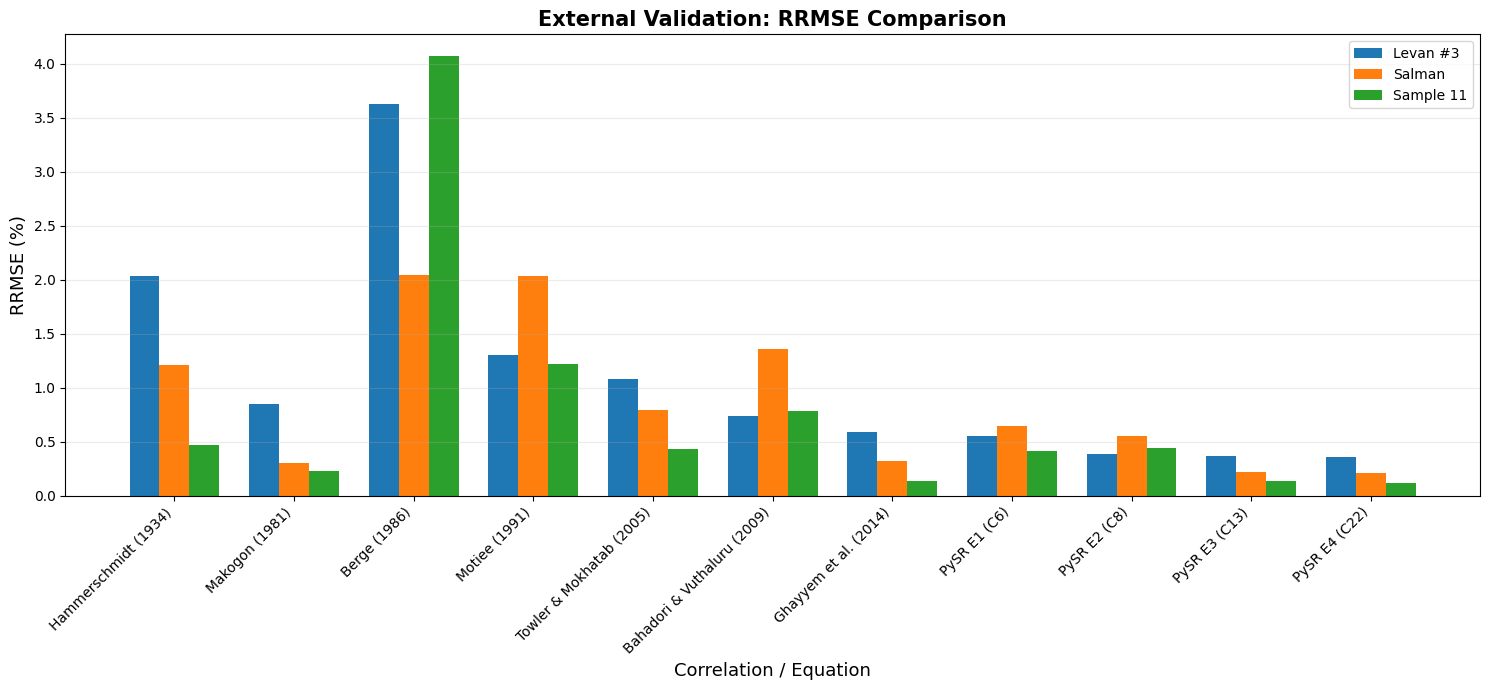

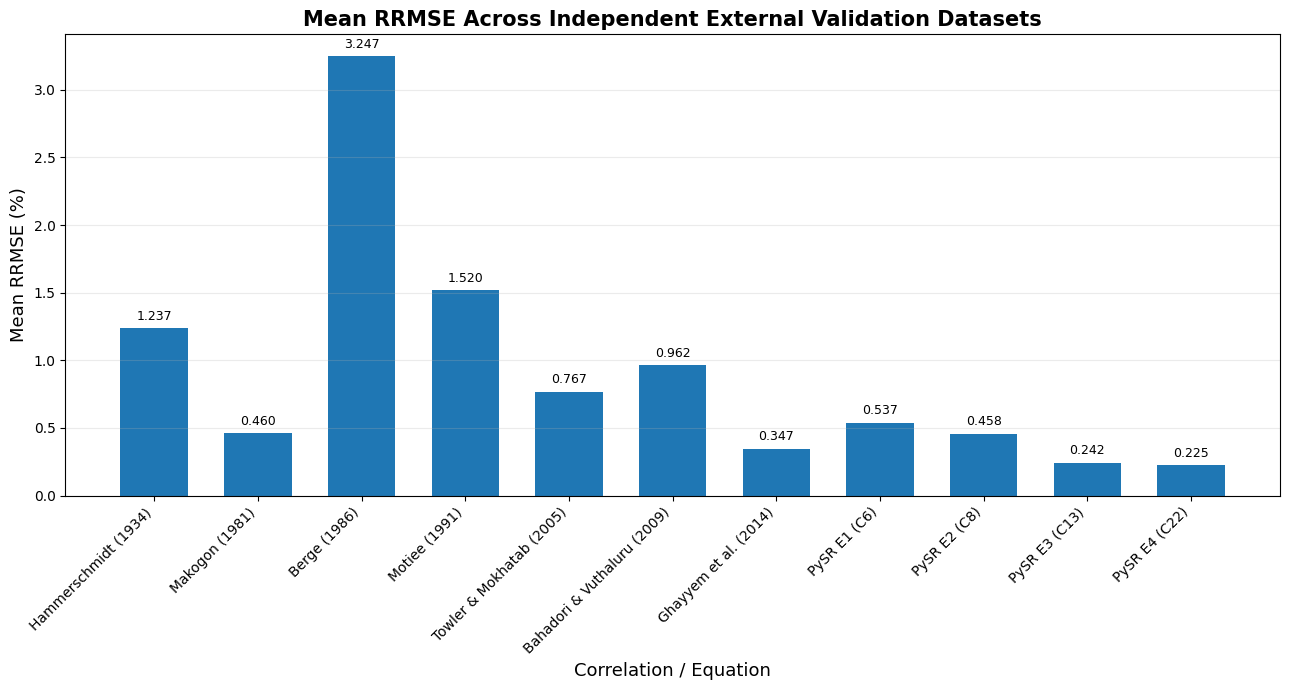

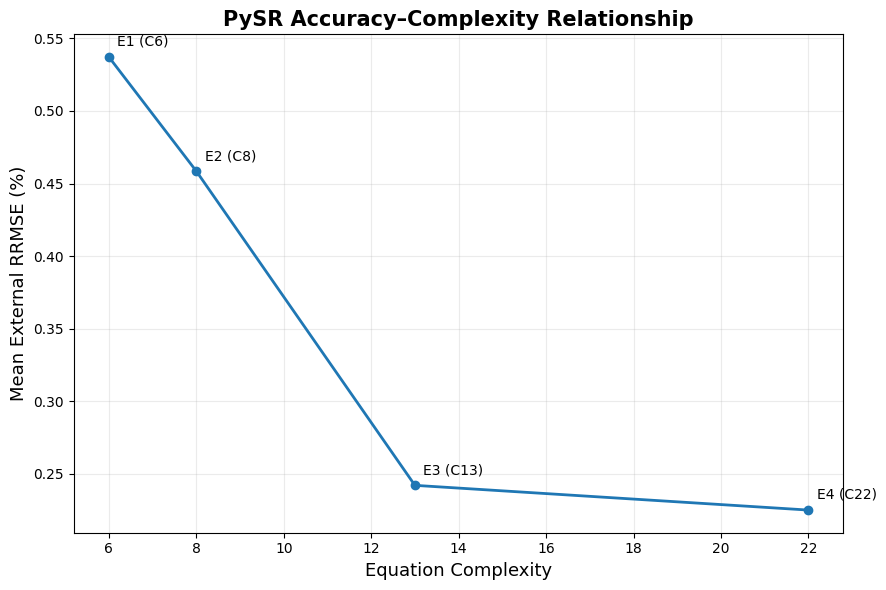


Graphs saved in:
C:\Users\lenovo\OneDrive\Desktop\paper 2 notebooks\graphs

Files:
1. External_Validation_RRMSE_All.png
2. Mean_External_RRMSE.png
3. PySR_Accuracy_Complexity.png
4. External_RRMSE_Comparison.csv


In [14]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# ============================================================
# RRMSE (%) — Literature Equations vs PySR
# ============================================================

results = pd.DataFrame({
    "Model": [
        "Hammerschmidt (1934)",
        "Makogon (1981)",
        "Berge (1986)",
        "Motiee (1991)",
        "Towler & Mokhatab (2005)",
        "Bahadori & Vuthaluru (2009)",
        "Ghayyem et al. (2014)",
        "PySR E1 (C6)",
        "PySR E2 (C8)",
        "PySR E3 (C13)",
        "PySR E4 (C22)"
    ],

    "Type": [
        "Literature","Literature","Literature","Literature",
        "Literature","Literature","Literature",
        "PySR","PySR","PySR","PySR"
    ],

    "Complexity": [
        np.nan,np.nan,np.nan,np.nan,np.nan,np.nan,np.nan,
        6,8,13,22
    ],

    "Levan_3": [
        2.0322,0.8464,3.6295,1.3037,1.0843,0.7390,0.5853,
        0.5564,0.3827,0.3647,0.3531
    ],

    "Salman": [
        1.2112,0.3059,2.0427,2.0378,0.7887,1.3615,0.3169,
        0.6429,0.5537,0.2229,0.2072
    ],

    "Sample_11": [
        0.4665,0.2272,4.0695,1.2194,0.4277,0.7859,0.1390,
        0.4122,0.4391,0.1385,0.1147
    ]
})

# ============================================================
# Mean RRMSE across the three external datasets
# ============================================================

results["Mean_RRMSE"] = results[
    ["Levan_3","Salman","Sample_11"]
].mean(axis=1)

print("\n==============================================")
print("EXTERNAL VALIDATION — RRMSE")
print("==============================================\n")

print(
    results[
        ["Model","Type","Levan_3","Salman","Sample_11","Mean_RRMSE"]
    ].round(4).to_string(index=False)
)


# ============================================================
# Output folder
# ============================================================

out = Path("graphs")
out.mkdir(exist_ok=True)


# ============================================================
# GRAPH 1
# RRMSE for each external validation sample
# ============================================================

x = np.arange(len(results))
width = 0.25

fig, ax = plt.subplots(figsize=(15,7))

ax.bar(
    x - width,
    results["Levan_3"],
    width,
    label="Levan #3"
)

ax.bar(
    x,
    results["Salman"],
    width,
    label="Salman"
)

ax.bar(
    x + width,
    results["Sample_11"],
    width,
    label="Sample 11"
)

ax.set_ylabel("RRMSE (%)", fontsize=13)
ax.set_xlabel("Correlation / Equation", fontsize=13)
ax.set_title(
    "External Validation: RRMSE Comparison",
    fontsize=15,
    fontweight="bold"
)

ax.set_xticks(x)
ax.set_xticklabels(
    results["Model"],
    rotation=45,
    ha="right"
)

ax.legend()
ax.grid(axis="y", alpha=0.25)

plt.tight_layout()

plt.savefig(
    out / "External_Validation_RRMSE_All.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# GRAPH 2
# Mean external RRMSE
# ============================================================

fig, ax = plt.subplots(figsize=(13,7))

x = np.arange(len(results))

ax.bar(
    x,
    results["Mean_RRMSE"],
    width=0.65
)

ax.set_ylabel("Mean RRMSE (%)", fontsize=13)
ax.set_xlabel("Correlation / Equation", fontsize=13)

ax.set_title(
    "Mean RRMSE Across Independent External Validation Datasets",
    fontsize=15,
    fontweight="bold"
)

ax.set_xticks(x)
ax.set_xticklabels(
    results["Model"],
    rotation=45,
    ha="right"
)

ax.grid(axis="y", alpha=0.25)

# Add values above bars
for i, value in enumerate(results["Mean_RRMSE"]):
    ax.text(
        i,
        value + 0.04,
        f"{value:.3f}",
        ha="center",
        va="bottom",
        fontsize=9
    )

plt.tight_layout()

plt.savefig(
    out / "Mean_External_RRMSE.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# GRAPH 3
# PySR accuracy-complexity relationship
# ============================================================

pysr = results[results["Type"] == "PySR"].copy()

fig, ax = plt.subplots(figsize=(9,6))

ax.plot(
    pysr["Complexity"],
    pysr["Mean_RRMSE"],
    marker="o",
    linewidth=2
)

for _, row in pysr.iterrows():

    ax.annotate(
        row["Model"].replace("PySR ",""),
        (row["Complexity"], row["Mean_RRMSE"]),
        xytext=(6,8),
        textcoords="offset points",
        fontsize=10
    )

ax.set_xlabel("Equation Complexity", fontsize=13)
ax.set_ylabel("Mean External RRMSE (%)", fontsize=13)

ax.set_title(
    "PySR Accuracy–Complexity Relationship",
    fontsize=15,
    fontweight="bold"
)

ax.grid(True, alpha=0.25)

plt.tight_layout()

plt.savefig(
    out / "PySR_Accuracy_Complexity.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# Save numerical results
# ============================================================

results.to_csv(
    out / "External_RRMSE_Comparison.csv",
    index=False
)

print("\n==============================================")
print("Graphs saved in:")
print(out.resolve())
print("==============================================")

print("\nFiles:")
print("1. External_Validation_RRMSE_All.png")
print("2. Mean_External_RRMSE.png")
print("3. PySR_Accuracy_Complexity.png")
print("4. External_RRMSE_Comparison.csv")